# BNET Static Pipeline and Variable-Weight SCPI Test

This notebook tests the BNET SCPI/API additions for:

- `BNET:WEIGHT:REUSE` / `BNET:WEIGHT:REUSE?`
- `BNET:PIPELINE` / `BNET:PIPELINE?`
- original DDR variable-weight mode (`CONFIG = 2`)
- static-weight frame pipeline mode (`CONFIG = 34`)

The checks here are control/status/read-pointer/timing checks. BNET output is still driven to the DAC path, so exact waveform validation should be done with the RF loopback notebook after this smoke test passes.

In [79]:
from __future__ import annotations

import sys
import time
from pathlib import Path

import numpy as np

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import redpitaya_scpi as scpi

RP_IP = "169.254.77.151"  # Change to your board IP if mDNS is not available.
RP_PORT = 5000
TIMEOUT_S = 10

VECTOR_LEN = 2048
INPUT_PRE_PAD = 100
INPUT_POST_PAD = 100
INPUT_ACTIVE_LEN = VECTOR_LEN - INPUT_PRE_PAD - INPUT_POST_PAD

ACQ_CAPTURE_SAMPLES = 16384
ACQ_DECIMATION = 1
ACQ_TRIGGER_SOURCE = "CH1_PE"
ACQ_TRIGGER_DELAY_SAMPLES = 8092 + 50
ACQ_TRIGGER_LEVEL = 0.6
STAGE_COUNT = int(np.log2(VECTOR_LEN))
SAMPLE_BYTES = VECTOR_LEN * 2
WEIGHT_WORDS = VECTOR_LEN * STAGE_COUNT
WEIGHT_BYTES = WEIGHT_WORDS * 2
UPLOAD_CHUNK_BYTES = 1024

print(f"Target: {RP_IP}:{RP_PORT}")
print(f"VECTOR_LEN={VECTOR_LEN}, STAGE_COUNT={STAGE_COUNT}, WEIGHT_BYTES={WEIGHT_BYTES}")

Target: 169.254.77.151:5000
VECTOR_LEN=2048, STAGE_COUNT=11, WEIGHT_BYTES=45056


## Connect and Basic SCPI Helpers

In [80]:
rp = scpi.scpi(RP_IP, timeout=TIMEOUT_S, port=RP_PORT)

def cmd(command: str) -> None:
    print(f">> {command}")
    rp.tx_txt(command)

def query(command: str) -> str:
    print(f">> {command}")
    value = rp.txrx_txt(command).strip()
    print(f"<< {value}")
    return value

def query_int(command: str) -> int:
    text = query(command)
    return int(text, 0)

def strict_cmd(command: str) -> None:
    cmd(command)
    time.sleep(0.01)

def wait_for_bnet_done(timeout_s: float = 10.0) -> int:
    deadline = time.time() + timeout_s
    last_status = 0
    while time.time() < deadline:
        last_status = query_int("BNET:STATUS?")
        if last_status & 0x2:
            return last_status
        time.sleep(0.05)
    raise TimeoutError(f"BNET did not reach done before timeout; last STATUS=0x{last_status:x}")

def snapshot(label: str) -> dict[str, int]:
    data = {
        "status": query_int("BNET:STATUS?"),
        "config": query_int("BNET:CONFIG?"),
        "error": query_int("BNET:ERROR?"),
        "stream0_status": query_int("BNET:STREAM0:STATUS?"),
        "stream1_status": query_int("BNET:STREAM1:STATUS?"),
        "stream0_rptr": query_int("BNET:STREAM0:RPTR?"),
        "stream1_rptr": query_int("BNET:STREAM1:RPTR?"),
        "time_total": query_int("BNET:TIME0?"),
        "time_load": query_int("BNET:TIME1?"),
        "time_compute": query_int("BNET:TIME2?"),
        "time_playback": query_int("BNET:TIME3?"),
    }
    print(label)
    for key, value in data.items():
        print(f"  {key:16s} = {value} (0x{value:x})")
    return data

print("Connected")

Connected


## Fixed-Point Test Payloads

Weights use the existing packed 14-bit lane format:

- bits `[13:7]`: signed Q1.6 contribution to `y0`
- bits `[6:0]`: signed Q1.6 contribution to `y1`

The generated weight set is near-identity for every stage, using `63/64` because signed 7-bit Q1.6 cannot represent exactly `+1.0`.

In [81]:
def clip_i14(values: np.ndarray) -> np.ndarray:
    return np.clip(np.rint(values), -8192, 8191).astype(np.int16)

def pack_weight_word(y0_weight: int, y1_weight: int) -> np.int16:
    high = int(y0_weight) & 0x7f
    low = int(y1_weight) & 0x7f
    packed_u14 = (high << 7) | low
    return np.int16(packed_u14 if packed_u14 < 0x2000 else packed_u14 - 0x4000)

def unpack_s7(value: int) -> int:
    value &= 0x7f
    return value - 0x80 if value & 0x40 else value

def make_test_input(vector_len: int = VECTOR_LEN) -> np.ndarray:
    if vector_len != VECTOR_LEN:
        raise ValueError("This padded RF test assumes the configured VECTOR_LEN")
    values = np.zeros(vector_len, dtype=np.int16)
    n = np.arange(INPUT_ACTIVE_LEN)
    active = clip_i14(2500 + 1800 * np.sin(2 * np.pi * n / 97.0) + 700 * np.sin(2 * np.pi * n / 31.0))
    values[INPUT_PRE_PAD:INPUT_PRE_PAD + INPUT_ACTIVE_LEN] = active
    return values

def make_near_identity_weights(vector_len: int = VECTOR_LEN) -> np.ndarray:
    stage_count = int(np.log2(vector_len))
    weights = np.zeros(vector_len * stage_count, dtype=np.int16)
    one = 63
    zero = 0
    for stage in range(stage_count):
        half_span = 1 << stage
        base = stage * vector_len
        for pair in range(vector_len // 2):
            pair_in_group = pair & (half_span - 1)
            group_base = (pair - pair_in_group) << 1
            addr_a = group_base + pair_in_group
            addr_b = addr_a + half_span
            weights[base + addr_a] = pack_weight_word(one, zero)
            weights[base + addr_b] = pack_weight_word(zero, one)
    return weights

def butterfly_reference_i14(samples_i14: np.ndarray, packed_weights: np.ndarray) -> np.ndarray:
    data = np.asarray(samples_i14, dtype=np.int64).copy()
    vector_len = data.size
    stage_count = int(np.log2(vector_len))
    packed = np.asarray(packed_weights, dtype=np.int16).astype(np.int64)
    assert packed.size == vector_len * stage_count
    for stage in range(stage_count):
        half_span = 1 << stage
        old = data.copy()
        base = stage * vector_len
        for pair in range(vector_len // 2):
            pair_in_group = pair & (half_span - 1)
            group_base = (pair - pair_in_group) << 1
            addr_a = group_base + pair_in_group
            addr_b = addr_a + half_span
            wa = int(packed[base + addr_a]) & 0x3fff
            wb = int(packed[base + addr_b]) & 0x3fff
            y0 = old[addr_a] * unpack_s7(wa >> 7) + old[addr_b] * unpack_s7(wb >> 7)
            y1 = old[addr_a] * unpack_s7(wa) + old[addr_b] * unpack_s7(wb)
            data[addr_a] = np.clip((y0 + 32) >> 6, -8192, 8191)
            data[addr_b] = np.clip((y1 + 32) >> 6, -8192, 8191)
    return data.astype(np.int16)

def pack_i16_le(values: np.ndarray) -> bytes:
    return np.asarray(values, dtype="<i2").tobytes()

input_samples = make_test_input()
weights = make_near_identity_weights()
reference = butterfly_reference_i14(input_samples, weights)

print(input_samples[:8])
print(weights[:8])
print(reference[:8])

[0 0 0 0 0 0 0 0]
[8064   63 8064   63 8064   63 8064   63]
[0 0 0 0 0 0 0 0]


## DDR Upload Helpers

In [82]:
def align_up(value: int, alignment: int) -> int:
    return (value + alignment - 1) & ~(alignment - 1)

def release_slot(slot: int) -> None:
    try:
        strict_cmd(f"BNET:DDR:SLOT{slot}:RELEASE")
    except Exception as exc:
        print(f"Ignoring slot {slot} release failure: {exc}")

def reserve_bnet_slot(slot: int, address: int, size_bytes: int) -> None:
    strict_cmd(f"BNET:DDR:SLOT{slot}:RESERVE {address},{size_bytes}")

def upload_bnet_slot_bytes(slot: int, offset_bytes: int, data: bytes) -> None:
    for chunk_offset in range(0, len(data), UPLOAD_CHUNK_BYTES):
        chunk = data[chunk_offset:chunk_offset + UPLOAD_CHUNK_BYTES]
        payload = ",".join(str(b) for b in chunk)
        strict_cmd(f"BNET:DDR:SLOT{slot}:OFFSET{offset_bytes + chunk_offset}:DATA{len(chunk)} {payload}")

def attach_slot_to_stream(slot: int, stream: int, buffer: int = 0) -> None:
    strict_cmd(f"BNET:DDR:SLOT{slot}:STREAM{stream}:BUF{buffer}")

def prepare_ddr_buffers(input_i16: np.ndarray, weight_i16: np.ndarray) -> tuple[int, int]:
    ddr_start = query_int("BNET:DDR:START?")
    ddr_size = query_int("BNET:DDR:SIZE?")
    sample_data = pack_i16_le(input_i16)
    weight_data = pack_i16_le(weight_i16)
    sample_addr = align_up(ddr_start, 0x1000)
    weight_addr = align_up(sample_addr + len(sample_data), 0x1000)
    required_end = weight_addr + len(weight_data)
    if required_end > ddr_start + ddr_size:
        raise RuntimeError("BNET DDR test buffers do not fit in reported DDR region")

    release_slot(0)
    release_slot(1)
    reserve_bnet_slot(0, sample_addr, len(sample_data))
    reserve_bnet_slot(1, weight_addr, len(weight_data))
    upload_bnet_slot_bytes(0, 0, sample_data)
    upload_bnet_slot_bytes(1, 0, weight_data)
    attach_slot_to_stream(0, stream=0, buffer=0)
    attach_slot_to_stream(1, stream=1, buffer=0)
    return sample_addr, weight_addr

## New Command Smoke Test

This cell proves that the new SCPI handlers are present and that they manipulate the expected config bits.

In [83]:
strict_cmd("BNET:RST")
strict_cmd("BNET:MODE DDR")
assert query("BNET:MODE?") == "DDR"

strict_cmd("BNET:WEIGHT:REUSE 0")
assert query_int("BNET:WEIGHT:REUSE?") == 0
strict_cmd("BNET:WEIGHT:REUSE 1")
assert query_int("BNET:WEIGHT:REUSE?") == 1
assert query_int("BNET:CONFIG?") == 18

strict_cmd("BNET:WEIGHT:REUSE 0")
strict_cmd("BNET:PIPELINE 0")
assert query_int("BNET:PIPELINE?") == 0
assert query_int("BNET:CONFIG?") == 2

strict_cmd("BNET:PIPELINE 1")
assert query_int("BNET:PIPELINE?") == 1
assert query_int("BNET:CONFIG?") == 34

strict_cmd("BNET:PIPELINE 0")
assert query_int("BNET:CONFIG?") == 2
print("New command smoke test passed")

>> BNET:RST
>> BNET:MODE DDR
>> BNET:MODE?
<< DDR
>> BNET:WEIGHT:REUSE 0
>> BNET:WEIGHT:REUSE?
<< 0
>> BNET:WEIGHT:REUSE 1
>> BNET:WEIGHT:REUSE?
<< 1
>> BNET:CONFIG?
<< 18
>> BNET:WEIGHT:REUSE 0
>> BNET:PIPELINE 0
>> BNET:PIPELINE?
<< 0
>> BNET:CONFIG?
<< 2
>> BNET:PIPELINE 1
>> BNET:PIPELINE?
<< 1
>> BNET:CONFIG?
<< 34
>> BNET:PIPELINE 0
>> BNET:CONFIG?
<< 2
New command smoke test passed


## Shared DDR Run Helper

In [84]:
def run_bnet_ddr_mode(label: str, pipeline: bool) -> dict[str, int]:
    strict_cmd("BNET:RST")
    prepare_ddr_buffers(input_samples, weights)

    strict_cmd(f"BNET:VLEN {VECTOR_LEN}")
    strict_cmd("BNET:STREAM0:FORMAT 0")
    strict_cmd("BNET:STREAM1:FORMAT 0")
    strict_cmd("BNET:STREAM0:ENABLE 1")
    strict_cmd("BNET:STREAM1:ENABLE 1")
    strict_cmd("BNET:STREAM0:COMMIT0")
    strict_cmd("BNET:STREAM1:COMMIT0")

    strict_cmd("BNET:MODE DDR")
    strict_cmd("BNET:WEIGHT:REUSE 0")
    strict_cmd(f"BNET:PIPELINE {1 if pipeline else 0}")
    expected_config = 34 if pipeline else 2
    observed_config = query_int("BNET:CONFIG?")
    assert observed_config == expected_config, (observed_config, expected_config)

    strict_cmd("BNET:START")
    status = wait_for_bnet_done(timeout_s=20.0)
    print(f"{label} completed with STATUS=0x{status:x}")
    result = snapshot(label)

    assert result["error"] == 0, result
    assert result["status"] & 0x2, result
    assert result["stream0_rptr"] >= SAMPLE_BYTES, result
    assert result["stream1_rptr"] >= WEIGHT_BYTES, result
    assert result["time_total"] > 0, result
    return result

## Test Original Variable-Weight DDR Mode

This is the existing training-friendly path: stream 0 supplies samples and stream 1 supplies the full staged weight stream on every run.

In [85]:
variable_result = run_bnet_ddr_mode("Variable-weight serial DDR mode", pipeline=False)
variable_result

>> BNET:RST
>> BNET:DDR:START?
<< 16777216
>> BNET:DDR:SIZE?
<< 33554432
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT1:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,4096
>> BNET:DDR:SLOT1:RESERVE 16781312,45056
>> BNET:DDR:SLOT0:OFFSET0:DATA1024 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,196,9,197,10,193,11,175,12,141,13,83,14,255,14,140,15,251,15,73,16,119,16,134,16,122,16,87,16,31,16,217,15,138,15,56,15,231,14,157,14,95,14,48,14,19,14,11,14,24,14,57,14,110,14,180,14,7,15,99,15,196,15,35,16,123,16,199,16,1,17,36,17,45,17,25,17,228,16,142,16,23,16,129,15,205,14,0,14,29,13,42,12,45,11,44,10,45,9,54,8,77,7,120,6,187,5,25,5,149,4,48,4,235,3,19

{'status': 18,
 'config': 2,
 'error': 0,
 'stream0_status': 4,
 'stream1_status': 4,
 'stream0_rptr': 4096,
 'stream1_rptr': 45056,
 'time_total': 112676,
 'time_load': 33828,
 'time_compute': 78848,
 'time_playback': 1024}

## Test Static Pipeline DDR Mode

This path sets `BNET:PIPELINE 1`, so the hardware should preload static weights from stream 1 and then process the frame through the static pipeline path.

In [86]:
pipeline_result = run_bnet_ddr_mode("Static-weight pipeline DDR mode", pipeline=True)
pipeline_result

>> BNET:RST
>> BNET:DDR:START?
<< 16777216
>> BNET:DDR:SIZE?
<< 33554432
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT1:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,4096
>> BNET:DDR:SLOT1:RESERVE 16781312,45056
>> BNET:DDR:SLOT0:OFFSET0:DATA1024 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,196,9,197,10,193,11,175,12,141,13,83,14,255,14,140,15,251,15,73,16,119,16,134,16,122,16,87,16,31,16,217,15,138,15,56,15,231,14,157,14,95,14,48,14,19,14,11,14,24,14,57,14,110,14,180,14,7,15,99,15,196,15,35,16,123,16,199,16,1,17,36,17,45,17,25,17,228,16,142,16,23,16,129,15,205,14,0,14,29,13,42,12,45,11,44,10,45,9,54,8,77,7,120,6,187,5,25,5,149,4,48,4,235,3,19

{'status': 2,
 'config': 34,
 'error': 0,
 'stream0_status': 4,
 'stream1_status': 4,
 'stream0_rptr': 4096,
 'stream1_rptr': 45056,
 'time_total': 1024,
 'time_load': 0,
 'time_compute': 0,
 'time_playback': 1024}

## Pipeline Instrumentation Notes

The current HDL exposes only `bnet_pipe_time_output_cycles` for the static pipeline path. In pipeline mode the top-level currently maps this value to both `BNET:TIME0?` and `BNET:TIME3?`, while `BNET:TIME1?` and `BNET:TIME2?` read as zero. That means this notebook can measure output-frame cycles and DDR read-pointer behavior, but true pipeline load/first-output/compute counters still need HDL instrumentation.

In [87]:
def explain_pipeline_timing(result: dict[str, int]) -> None:
    print("Pipeline timing interpretation")
    print(f"  TIME0 total register     : {result['time_total']}")
    print(f"  TIME1 load register      : {result['time_load']} (not instrumented for pipeline yet)")
    print(f"  TIME2 compute register   : {result['time_compute']} (not instrumented for pipeline yet)")
    print(f"  TIME3 playback register  : {result['time_playback']}")
    assert result["time_total"] == result["time_playback"], result
    assert result["time_load"] == 0, result
    assert result["time_compute"] == 0, result

explain_pipeline_timing(pipeline_result)

Pipeline timing interpretation
  TIME0 total register     : 1024
  TIME1 load register      : 0 (not instrumented for pipeline yet)
  TIME2 compute register   : 0 (not instrumented for pipeline yet)
  TIME3 playback register  : 1024


## Test Second Pipeline Frame Without Reloading Weights

This is the key fixed-weight reuse test. It does **not** issue `BNET:RST`, and it disables stream 1. Only a new stream 0 input frame is uploaded and committed. If this completes, the pipeline kept its preloaded per-stage weights.

In [88]:
def prepare_sample_buffer_only(input_i16: np.ndarray) -> int:
    ddr_start = query_int("BNET:DDR:START?")
    sample_data = pack_i16_le(input_i16)
    sample_addr = align_up(ddr_start, 0x1000)

    release_slot(0)
    reserve_bnet_slot(0, sample_addr, len(sample_data))
    upload_bnet_slot_bytes(0, 0, sample_data)
    attach_slot_to_stream(0, stream=0, buffer=0)
    return sample_addr

def run_pipeline_second_frame_without_weight_reload() -> dict[str, int]:
    second_input = clip_i14(-input_samples)
    prepare_sample_buffer_only(second_input)

    strict_cmd("BNET:STREAM0:ENABLE 1")
    strict_cmd("BNET:STREAM1:ENABLE 0")
    strict_cmd("BNET:STREAM0:COMMIT0")
    strict_cmd("BNET:MODE DDR")
    strict_cmd("BNET:PIPELINE 1")
    strict_cmd("BNET:WEIGHT:REUSE 0")
    assert query_int("BNET:CONFIG?") == 34

    before_stream1_rptr = query_int("BNET:STREAM1:RPTR?")
    strict_cmd("BNET:START")
    status = wait_for_bnet_done(timeout_s=20.0)
    print(f"Second no-reset pipeline frame completed with STATUS=0x{status:x}")
    result = snapshot("Second no-reset static pipeline frame")

    assert result["error"] == 0, result
    assert result["status"] & 0x2, result
    assert result["stream0_rptr"] >= SAMPLE_BYTES, result
    assert result["stream1_rptr"] == before_stream1_rptr, (before_stream1_rptr, result)
    assert result["time_playback"] == VECTOR_LEN // 2, result
    return result

pipeline_second_result = run_pipeline_second_frame_without_weight_reload()
pipeline_second_result

>> BNET:DDR:START?


<< 16777216
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,4096
>> BNET:DDR:SLOT0:OFFSET0:DATA1024 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,60,246,59,245,63,244,81,243,115,242,173,241,1,241,116,240,5,240,183,239,137,239,122,239,134,239,169,239,225,239,39,240,118,240,200,240,25,241,99,241,161,241,208,241,237,241,245,241,232,241,199,241,146,241,76,241,249,240,157,240,60,240,221,239,133,239,57,239,255,238,220,238,211,238,231,238,28,239,114,239,233,239,127,240,51,241,0,242,227,242,214,243,211,244,212,245,211,246,202,247,179,248,136,249,69,250,231,250,107,251,208,251,21,252,60,252,70,252,56,252,20,252,224,251,161,251,92,251,

{'status': 2,
 'config': 34,
 'error': 0,
 'stream0_status': 4,
 'stream1_status': 0,
 'stream0_rptr': 4096,
 'stream1_rptr': 45056,
 'time_total': 1024,
 'time_load': 0,
 'time_compute': 0,
 'time_playback': 1024}

## Optional RF Loopback Output Validation

Set `RUN_RF_LOOPBACK = True` only when RF OUT1 is physically connected to RF IN1. This captures the DAC output shape, plots it against the PC-side fixed-point reference, and searches for the best delay/sign alignment. It is intentionally diagnostic rather than pass/fail because low correlation can come from offset, inversion, trigger delay, clipping, stale DAC output, or a real hardware-compute mismatch.

>> BNET:RST
>> BNET:DDR:START?
<< 16777216
>> BNET:DDR:SIZE?
<< 33554432
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT1:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,4096
>> BNET:DDR:SLOT1:RESERVE 16781312,45056
>> BNET:DDR:SLOT0:OFFSET0:DATA1024 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,196,9,197,10,193,11,175,12,141,13,83,14,255,14,140,15,251,15,73,16,119,16,134,16,122,16,87,16,31,16,217,15,138,15,56,15,231,14,157,14,95,14,48,14,19,14,11,14,24,14,57,14,110,14,180,14,7,15,99,15,196,15,35,16,123,16,199,16,1,17,36,17,45,17,25,17,228,16,142,16,23,16,129,15,205,14,0,14,29,13,42,12,45,11,44,10,45,9,54,8,77,7,120,6,187,5,25,5,149,4,48,4,235,3,19

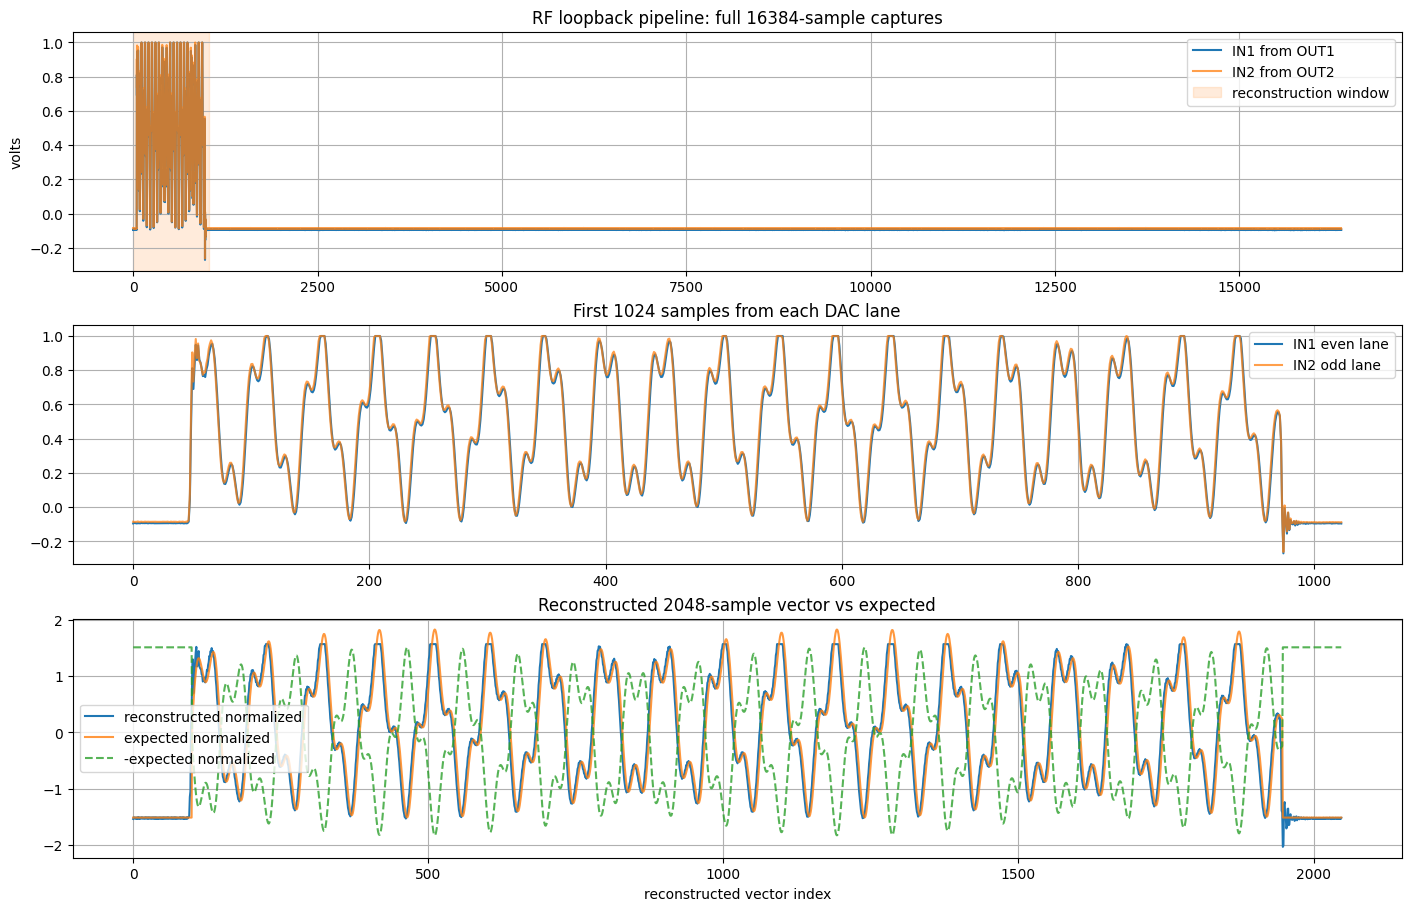

>> BNET:RST
>> BNET:DDR:START?
<< 16777216
>> BNET:DDR:SIZE?
<< 33554432
>> BNET:DDR:SLOT0:RELEASE
>> BNET:DDR:SLOT1:RELEASE
>> BNET:DDR:SLOT0:RESERVE 16777216,4096
>> BNET:DDR:SLOT1:RESERVE 16781312,45056
>> BNET:DDR:SLOT0:OFFSET0:DATA1024 0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,196,9,197,10,193,11,175,12,141,13,83,14,255,14,140,15,251,15,73,16,119,16,134,16,122,16,87,16,31,16,217,15,138,15,56,15,231,14,157,14,95,14,48,14,19,14,11,14,24,14,57,14,110,14,180,14,7,15,99,15,196,15,35,16,123,16,199,16,1,17,36,17,45,17,25,17,228,16,142,16,23,16,129,15,205,14,0,14,29,13,42,12,45,11,44,10,45,9,54,8,77,7,120,6,187,5,25,5,149,4,48,4,235,3,19

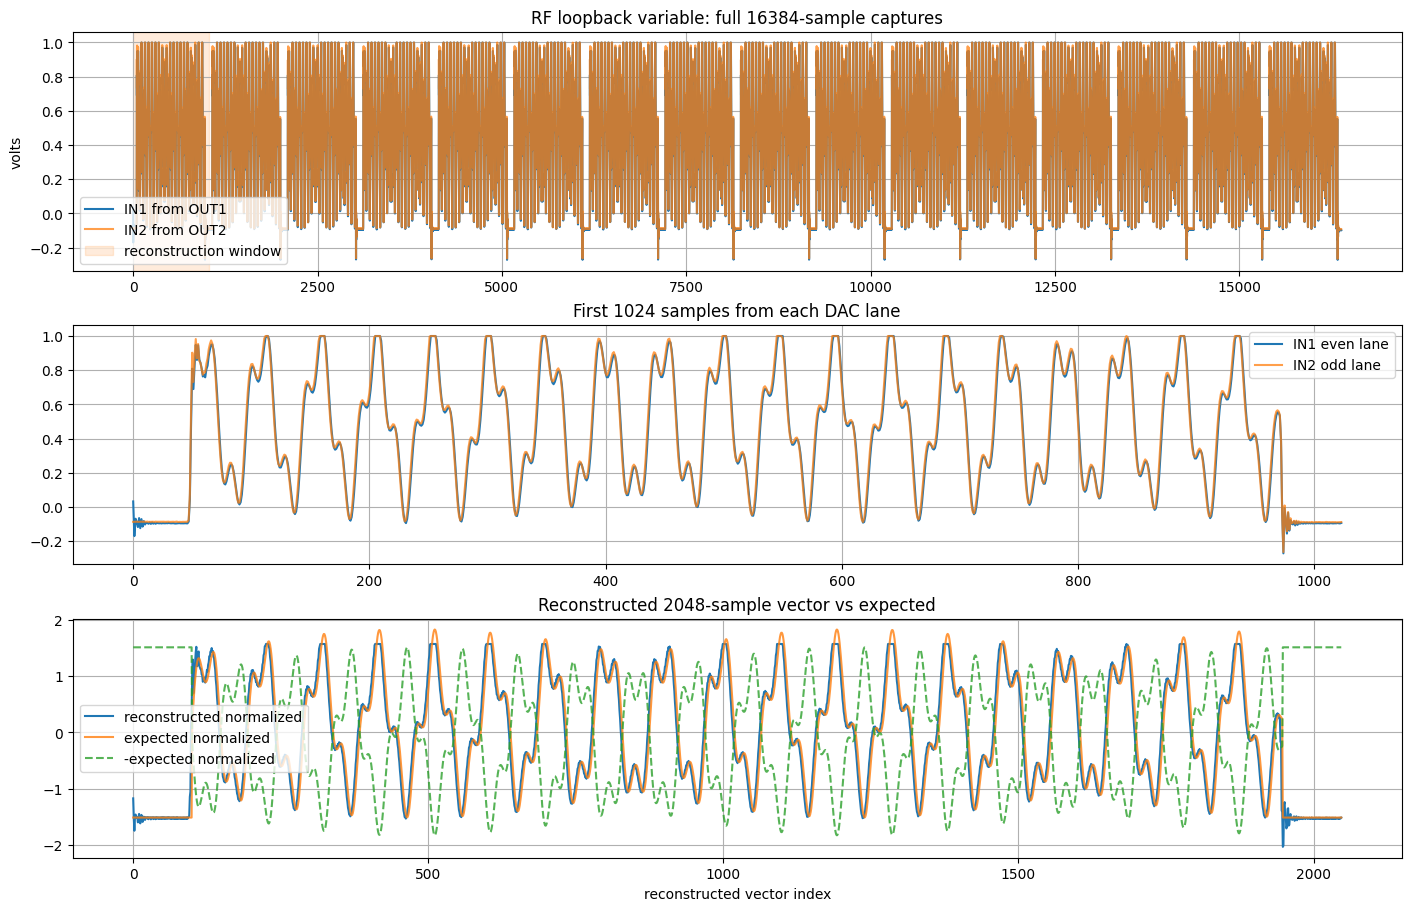

RF loopback comparison
pipeline: polarity=normal   direct= 0.9723 inverted=-0.9723 best_abs= 0.9723
variable: polarity=normal   direct= 0.9723 inverted=-0.9723 best_abs= 0.9723


{'pipeline': {'mode': 'pipeline',
  'passed': True,
  'polarity': 'normal',
  'direct_correlation': 0.9722916227967611,
  'inverted_correlation': -0.9722916227967611,
  'best_abs_correlation': 0.9722916227967611,
  'analysis_start': 0,
  'lane_samples': 1024,
  'reconstructed_samples': 2048,
  'captured_samples_ch1': 16384,
  'captured_samples_ch2': 16384,
  'reconstructed_std': 0.35240061954415214,
  'reconstructed_pkpk': 1.269409,
  'run': {'status': 2,
   'config': 34,
   'error': 0,
   'stream0_status': 4,
   'stream1_status': 4,
   'stream0_rptr': 4096,
   'stream1_rptr': 45056,
   'time_total': 1024,
   'time_load': 0,
   'time_compute': 0,
   'time_playback': 1024}},
 'variable': {'mode': 'variable',
  'passed': True,
  'polarity': 'normal',
  'direct_correlation': 0.9722570396746785,
  'inverted_correlation': -0.9722570396746785,
  'best_abs_correlation': 0.9722570396746785,
  'analysis_start': 0,
  'lane_samples': 1024,
  'reconstructed_samples': 2048,
  'captured_samples_ch1'

In [89]:
import matplotlib.pyplot as plt

RUN_RF_LOOPBACK = True
RF_ASSERT_CORRELATION = False
RF_CORR_THRESHOLD = 0.80
RF_ANALYSIS_START = 0
RF_ANALYSIS_SAMPLES = VECTOR_LEN // 2

def parse_redpitaya_data(text: str) -> np.ndarray:
    stripped = text.strip().strip("{}")
    if not stripped:
        return np.array([], dtype=np.float64)
    return np.array([float(item) for item in stripped.split(",") if item.strip()], dtype=np.float64)

def normalized_correlation(a: np.ndarray, b: np.ndarray) -> float:
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    n = min(a.size, b.size)
    if n == 0:
        return 0.0
    a = a[:n] - np.mean(a[:n])
    b = b[:n] - np.mean(b[:n])
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return 0.0 if denom == 0 else float(np.dot(a, b) / denom)

def describe_waveform(name: str, values: np.ndarray) -> None:
    values = np.asarray(values, dtype=np.float64)
    print(
        f"{name:18s}: n={values.size}, min={np.min(values): .6f}, "
        f"max={np.max(values): .6f}, mean={np.mean(values): .6f}, "
        f"std={np.std(values): .6f}, pkpk={np.ptp(values): .6f}"
    )

def capture_window(capture: np.ndarray) -> np.ndarray:
    start = RF_ANALYSIS_START
    stop = start + RF_ANALYSIS_SAMPLES
    window = np.asarray(capture, dtype=np.float64)[start:stop]
    if window.size != RF_ANALYSIS_SAMPLES:
        raise RuntimeError(f"Expected {RF_ANALYSIS_SAMPLES} analysis samples, got {window.size}")
    return window

def reconstruct_dual_output(ch1: np.ndarray, ch2: np.ndarray) -> np.ndarray:
    ch1_window = capture_window(ch1)
    ch2_window = capture_window(ch2)
    reconstructed = np.empty(VECTOR_LEN, dtype=np.float64)
    reconstructed[0::2] = ch1_window
    reconstructed[1::2] = ch2_window
    return reconstructed

def normalize(values: np.ndarray) -> np.ndarray:
    values = np.asarray(values, dtype=np.float64)
    std = float(np.std(values))
    return np.zeros_like(values) if std == 0.0 else (values - np.mean(values)) / std

def plot_rf_diagnostics(ch1: np.ndarray, ch2: np.ndarray, reconstructed: np.ndarray, expected: np.ndarray, title: str) -> None:
    fig, axes = plt.subplots(3, 1, figsize=(14, 9), constrained_layout=True)
    window_stop = RF_ANALYSIS_START + RF_ANALYSIS_SAMPLES

    axes[0].plot(ch1, label="IN1 from OUT1")
    axes[0].plot(ch2, label="IN2 from OUT2", alpha=0.75)
    axes[0].axvspan(RF_ANALYSIS_START, window_stop, color="tab:orange", alpha=0.15, label="reconstruction window")
    axes[0].set_title(f"{title}: full {ch1.size}-sample captures")
    axes[0].set_ylabel("volts")
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(capture_window(ch1), label="IN1 even lane")
    axes[1].plot(capture_window(ch2), label="IN2 odd lane", alpha=0.75)
    axes[1].set_title("First 1024 samples from each DAC lane")
    axes[1].grid(True)
    axes[1].legend()

    axes[2].plot(normalize(reconstructed), label="reconstructed normalized")
    axes[2].plot(normalize(expected), label="expected normalized", alpha=0.8)
    axes[2].plot(normalize(-expected), "--", label="-expected normalized", alpha=0.8)
    axes[2].set_title("Reconstructed 2048-sample vector vs expected")
    axes[2].set_xlabel("reconstructed vector index")
    axes[2].grid(True)
    axes[2].legend()
    plt.show()

def arm_rf_acquisition() -> None:
    strict_cmd("ACQ:RST")
    strict_cmd(f"ACQ:DEC:Factor {ACQ_DECIMATION}")
    strict_cmd("ACQ:DATA:Units VOLTS")
    strict_cmd("ACQ:DATA:FORMAT ASCII")
    strict_cmd(f"ACQ:TRig:LEV {ACQ_TRIGGER_LEVEL}")
    strict_cmd(f"ACQ:TRig:DLY {ACQ_TRIGGER_DELAY_SAMPLES}")
    strict_cmd("ACQ:START")
    strict_cmd(f"ACQ:TRig {ACQ_TRIGGER_SOURCE}")
    time.sleep(0.05)
    state = query("ACQ:TRig:STAT?")
    if state.upper().startswith("TD"):
        raise RuntimeError("Acquisition triggered before BNET:START. Raise ACQ_TRIGGER_LEVEL or check IN1 noise/DC level.")

def wait_for_rf_capture(timeout_s: float = 10.0) -> tuple[np.ndarray, np.ndarray]:
    deadline = time.time() + timeout_s
    while time.time() < deadline:
        state = query("ACQ:TRig:STAT?")
        if state.upper().startswith("TD"):
            break
        time.sleep(0.05)
    else:
        raise TimeoutError("Acquisition did not trigger on CH1_PE")

    while time.time() < deadline:
        if query("ACQ:TRig:FILL?").strip() == "1":
            break
        time.sleep(0.05)
    else:
        raise TimeoutError("Acquisition triggered but buffer did not fill")

    ch1 = parse_redpitaya_data(query("ACQ:SOUR1:DATA?"))
    ch2 = parse_redpitaya_data(query("ACQ:SOUR2:DATA?"))
    for name, capture in [("CH1", ch1), ("CH2", ch2)]:
        if capture.size != ACQ_CAPTURE_SAMPLES:
            print(f"Warning: expected {ACQ_CAPTURE_SAMPLES} {name} samples, got {capture.size}")
    return ch1, ch2

def configure_bnet_for_rf_run(pipeline: bool) -> None:
    strict_cmd("BNET:RST")
    prepare_ddr_buffers(input_samples, weights)

    strict_cmd(f"BNET:VLEN {VECTOR_LEN}")
    strict_cmd("BNET:STREAM0:FORMAT 0")
    strict_cmd("BNET:STREAM1:FORMAT 0")
    strict_cmd("BNET:STREAM0:ENABLE 1")
    strict_cmd("BNET:STREAM1:ENABLE 1")
    strict_cmd("BNET:STREAM0:COMMIT0")
    strict_cmd("BNET:STREAM1:COMMIT0")
    strict_cmd("BNET:MODE DDR")
    strict_cmd("BNET:WEIGHT:REUSE 0")
    strict_cmd(f"BNET:PIPELINE {1 if pipeline else 0}")
    expected_config = 34 if pipeline else 2
    observed_config = query_int("BNET:CONFIG?")
    assert observed_config == expected_config, (observed_config, expected_config)

def validate_rf_loopback(mode_label: str, pipeline: bool) -> dict[str, float | int | bool | str | dict]:
    configure_bnet_for_rf_run(pipeline=pipeline)
    arm_rf_acquisition()
    strict_cmd("BNET:START")
    ch1, ch2 = wait_for_rf_capture(timeout_s=10.0)
    status = wait_for_bnet_done(timeout_s=20.0)
    print(f"RF validation {mode_label} BNET run completed with STATUS=0x{status:x}")
    run = snapshot(f"RF validation {mode_label} run")
    assert run["error"] == 0, run
    assert run["stream0_rptr"] >= SAMPLE_BYTES, run
    assert run["stream1_rptr"] >= WEIGHT_BYTES, run

    expected = reference.astype(np.float64)
    reconstructed = reconstruct_dual_output(ch1, ch2)
    direct_corr = normalized_correlation(reconstructed, expected)
    inverted_corr = normalized_correlation(reconstructed, -expected)
    best_abs_corr = max(abs(direct_corr), abs(inverted_corr))
    polarity = "normal" if abs(direct_corr) >= abs(inverted_corr) else "inverted"

    describe_waveform("capture CH1 full", ch1)
    describe_waveform("capture CH2 full", ch2)
    describe_waveform("CH1 even lane", capture_window(ch1))
    describe_waveform("CH2 odd lane", capture_window(ch2))
    describe_waveform("reconstructed", reconstructed)
    describe_waveform("expected", expected)
    print(f"Direct correlation   : {direct_corr:.4f}")
    print(f"Inverted correlation : {inverted_corr:.4f}")
    print(f"Best polarity        : {polarity} (abs_corr={best_abs_corr:.4f})")
    plot_rf_diagnostics(ch1, ch2, reconstructed, expected, f"RF loopback {mode_label}")

    passed = best_abs_corr > RF_CORR_THRESHOLD
    result = {
        "mode": mode_label,
        "passed": passed,
        "polarity": polarity,
        "direct_correlation": direct_corr,
        "inverted_correlation": inverted_corr,
        "best_abs_correlation": best_abs_corr,
        "analysis_start": RF_ANALYSIS_START,
        "lane_samples": RF_ANALYSIS_SAMPLES,
        "reconstructed_samples": int(reconstructed.size),
        "captured_samples_ch1": int(ch1.size),
        "captured_samples_ch2": int(ch2.size),
        "reconstructed_std": float(np.std(reconstructed)),
        "reconstructed_pkpk": float(np.ptp(reconstructed)),
        "run": run,
    }
    if RF_ASSERT_CORRELATION:
        assert passed, result
    elif not passed:
        print("Correlation is below threshold; inspect the plots and waveform stats above.")
    return result

if RUN_RF_LOOPBACK:
    rf_pipeline_result = validate_rf_loopback("pipeline", pipeline=True)
    rf_variable_result = validate_rf_loopback("variable", pipeline=False)
    print("RF loopback comparison")
    for result in [rf_pipeline_result, rf_variable_result]:
        print(
            f"{result['mode']:8s}: polarity={result['polarity']:8s} "
            f"direct={result['direct_correlation']: .4f} "
            f"inverted={result['inverted_correlation']: .4f} "
            f"best_abs={result['best_abs_correlation']: .4f}"
        )
    rf_result = {"pipeline": rf_pipeline_result, "variable": rf_variable_result}
else:
    rf_result = {"skipped": True}
    print("RF loopback validation skipped; set RUN_RF_LOOPBACK=True after connecting RF OUT1/OUT2 to RF IN1/IN2.")

rf_result


## Compare Timing Counters

This comparison includes the original serial path, the first pipeline run with weight preload, and the second pipeline run without stream 1 reload.

In [56]:
for key in ["time_total", "time_load", "time_compute", "time_playback", "stream0_rptr", "stream1_rptr"]:
    print(
        f"{key:16s} "
        f"variable={variable_result[key]:10d} "
        f"pipeline_load={pipeline_result[key]:10d} "
        f"pipeline_reuse={pipeline_second_result[key]:10d}"
    )

time_total       variable=    112677 pipeline_load=      1024 pipeline_reuse=      1024
time_load        variable=     33829 pipeline_load=         0 pipeline_reuse=         0
time_compute     variable=     78848 pipeline_load=         0 pipeline_reuse=         0
time_playback    variable=      1024 pipeline_load=      1024 pipeline_reuse=      1024
stream0_rptr     variable=      4096 pipeline_load=      4096 pipeline_reuse=      4096
stream1_rptr     variable=     45056 pipeline_load=     45056 pipeline_reuse=     45056
